## 6-8_Probabilistic_clustering_with_Gaussian_Mixture_Model

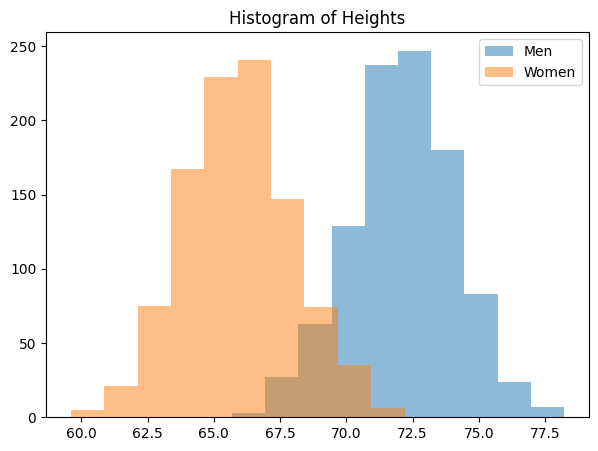

In [1]:
## 1. Generate normally distributed height data and visualize the histograms.

import numpy as np

N = 1000
in_m = 72
in_w = 66
s_m = 2
s_w = s_m
m = np.random.normal(in_m, s_m, N)
w = np.random.normal(in_w, s_w, N)
from matplotlib import pyplot as plt

%matplotlib inline
f, ax = plt.subplots(figsize=(7, 5))
ax.set_title("Histogram of Heights")
ax.hist(m, alpha=.5, label="Men");
ax.hist(w, alpha=.5, label="Women");
ax.legend()

In [2]:
## 2. Split the height data into training and test sets.

random_sample = np.random.choice([True, False], size=m.size)
m_test = m[random_sample]
m_train = m[~random_sample]
w_test = w[random_sample]
w_train = w[~random_sample]

In [3]:
## 3. Create normal probability distributions and calculate a probability density.

from scipy import stats
m_pdf = stats.norm(m_train.mean(), m_train.std())
w_pdf = stats.norm(w_train.mean(), w_train.std())
m_pdf.pdf(m[0])

np.float64(0.06770146027262473)

In [4]:
## 4. Calculate the probability density under the women's distribution.

w_pdf.pdf(m[0])

np.float64(1.2947606848415826e-05)

In [5]:
## 5. Classify male test samples by comparing probability densities.

guesses_m = np.ones_like(m_test)
guesses_m[m_pdf.pdf(m_test) < w_pdf.pdf(m_test)] = 0

In [6]:
## 6. Calculate the classification accuracy for male test samples.

guesses_m.mean()

np.float64(0.931640625)

In [7]:
## 7. Classify female test samples and calculate their accuracy.

guesses_w = np.ones_like(w_test)
guesses_w[m_pdf.pdf(w_test) > w_pdf.pdf(w_test)] = 0
guesses_w.mean()

np.float64(0.923828125)

In [8]:
## 8. Generate new height data with different standard deviations.

s_m = 1
s_w = 4
m = np.random.normal(in_m, s_m, N)
w = np.random.normal(in_w, s_w, N)

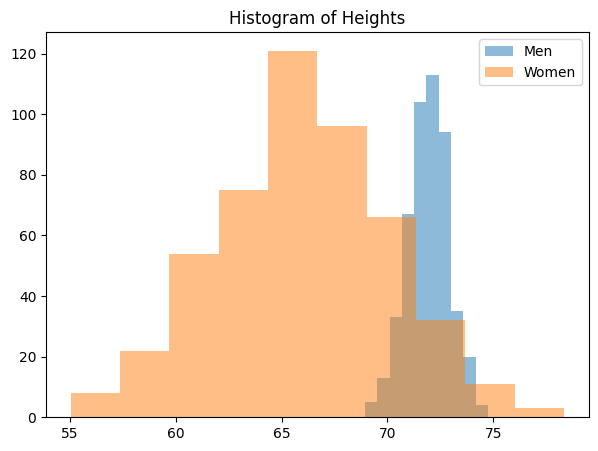

In [9]:
## 9. Split and visualize the new training distributions.

m_test = m[random_sample]
m_train = m[~random_sample]
w_test = w[random_sample]
w_train = w[~random_sample]
f, ax = plt.subplots(figsize=(7, 5))
ax.set_title("Histogram of Heights")
ax.hist(m_train, alpha=.5, label="Men");
ax.hist(w_train, alpha=.5, label="Women");
ax.legend()

C:\Users\toshi\AppData\Local\Temp\ipykernel_21036\4224435071.py:9: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x, m_pdf.pdf(x), 'k', linewidth=2, color='blue', label='Men')
C:\Users\toshi\AppData\Local\Temp\ipykernel_21036\4224435071.py:10: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x, w_pdf.pdf(x), 'k', linewidth=2, color='green',label='Women')


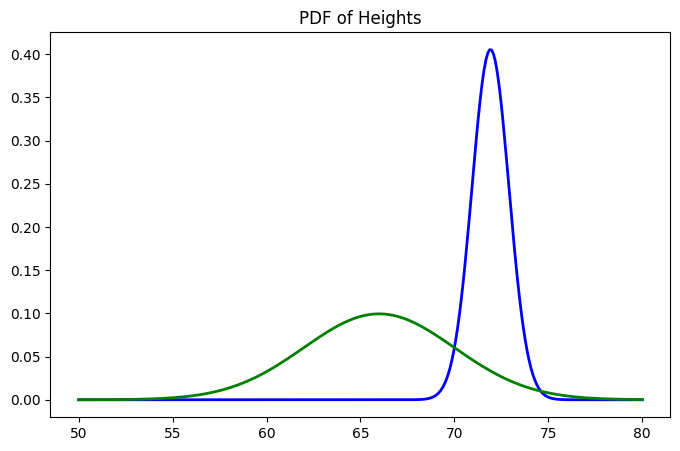

In [10]:
## 10. Plot the probability density functions of both height distributions.

m_pdf = stats.norm(m_train.mean(), m_train.std())
w_pdf = stats.norm(w_train.mean(), w_train.std())

x = np.linspace(50,80,300)
plt.figure(figsize=(8,5))
plt.title('PDF of Heights')
plt.plot(x, m_pdf.pdf(x), 'k', linewidth=2, color='blue', label='Men')
plt.plot(x, w_pdf.pdf(x), 'k', linewidth=2, color='green',label='Women')

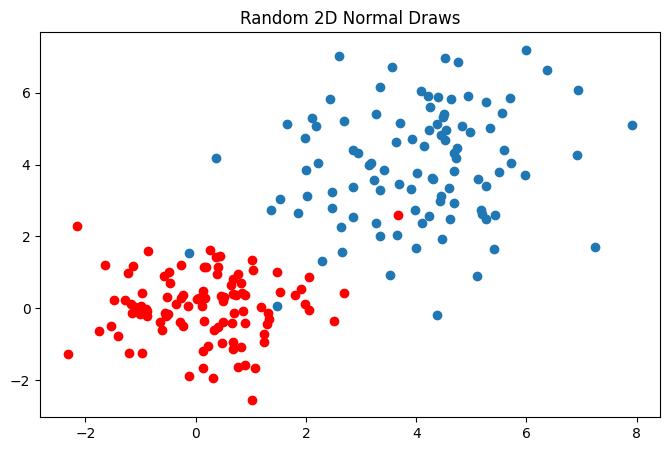

In [12]:
## 11. Generate and visualize two-dimensional Gaussian samples.

class_A = np.random.normal(0, 1, size=(100, 2))
class_B = np.random.normal(4, 1.5, size=(100, 2))
f, ax = plt.subplots(figsize=(8, 5))
plt.title('Random 2D Normal Draws')
ax.scatter(class_A[:,0], class_A[:,1], label='A', c='r')
ax.scatter(class_B[:,0], class_B[:,1], label='B')

In [13]:
## 12. Fit a Gaussian mixture model to the two-dimensional samples.

from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=2)
X = np.row_stack((class_A, class_B))
y = np.hstack((np.ones(100), np.zeros(100)))

train = np.random.choice([True, False], 200)
gmm.fit(X[train])

C:\Users\toshi\AppData\Local\Temp\ipykernel_21036\4237859839.py:5: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  X = np.row_stack((class_A, class_B))


,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None


In [14]:
## 13. Predict cluster labels for the first five training samples.

gmm.predict(X[train])[:5]

array([0, 0, 0, 0, 0])